# Science case: exoplanet atmospheres at high resolution with CSHELL

CSHELL at R = 43,000 (100 um slit) or R = 18,000 (bare fiber) covers 1.08-1.75 um, but its free
spectral range is only ~2.5e-3 lambda: **one setting is ~27 A wide at 1.08 um and ~40 A at 1.55 um**.
That rules out broad-band cross-correlation over hundreds of lines in one shot, and points to
**single strong features**. The best one is the metastable **He I 1083.3 nm triplet**, the
workhorse of escaping-atmosphere studies (Spake et al. 2018; Allart et al. 2018), where transit
depths of 0.5-5% over a ~1 A core are common for hot Jupiters and warm Neptunes.

**Assumptions used here** (knobs):

* He 10830 setting: 1081-1086 nm (vacuum), R = 43,000 and R = 18,000.
* Detection metric: the excess absorption averaged over `n_core` resels centred on the planet line
  (3 resels = 0.75 A at R = 43k, 2 resels = 1.2 A at R = 18k), measured in-transit minus
  out-of-transit with equal in/out exposure. Precision per transit:
  $\sigma = \sqrt{2}/(\mathrm{SNR}_{resel}\sqrt{n_{core}\,N_{exp,in}})$.
* The planet line is a Gaussian of 0.7 A FWHM (typical He 10830 width); the quoted literature
  depth is the peak depth, so the *measured* depth is the mean of that profile over the `n_core`
  window (0.79 at R = 43k, 0.59 at R = 18k). Instrumental LSF broadening is not added on top.
* Individual exposures of 300 s; split into reads only if the brightest pixel would saturate
  (`full_well` from the preset, placeholder 80 ke$^-$, 80% margin).
* Transit duration 2 h (24 in-transit exposures) and the same out of transit (1.8 h for HD 189733 b,
  2.7 h for WASP-107 b in reality).
* Not included, each a ~20-40% effect: the continuum SNR is used although the planet signal sits in
  the stellar He I line core (30-50% deep in K dwarfs); the OH airglow doublet at 10832/10834 A and
  the H$_2$O tellurics near the line; the array-wide LSF.
* Slit throughput for R = 43,000 is a placeholder (0.5) until measured.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude
try:
    plt.style.use('gks')
except OSError:
    pass

In [2]:
# ---- knobs ----
N_TEL = 20
EXP = 300.0                  # s per exposure
T_TRANSIT = 2*3600           # s in transit (same out of transit)
LINE_FWHM_A = 0.7            # He 10830 planet line FWHM
HE_NM = 1083.3               # vacuum
MARGIN = 0.8                 # fraction of full well allowed
N_CORE = {"cshell_r43000": 3, "cshell_r18000": 2}   # resels averaged over the line core
from scipy.special import erf

N_IN = int(T_TRANSIT/EXP)    # in-transit exposures per transit

def he_setup(name, n_tel=N_TEL):
    return LFASTETC(name, n_telescopes=n_tel, wavelength_min_nm=1081, wavelength_max_nm=1086)

def core_fraction(etc, n_core):
    """Mean of a Gaussian line (peak 1, FWHM LINE_FWHM_A) over n_core resels centred on it."""
    sigma = LINE_FWHM_A/2.3548/10          # nm
    half = n_core*HE_NM/etc.instrument.resolving_power/2
    return sigma*np.sqrt(2*np.pi)/(2*half) * erf(half/(sigma*np.sqrt(2)))

def precision_per_transit(etc, src, exp=EXP, n_in=N_IN):
    """(sigma on the measured depth per transit, continuum SNR/resel/exposure, reads per exposure)."""
    n_exp = etc.reads_needed(src, exp, margin=MARGIN)
    r = etc.snr(src, exp, n_exp=n_exp)
    snr = r.at(HE_NM)["snr"]
    n_core = N_CORE[etc.instrument.name]
    return np.sqrt(2) / (snr*np.sqrt(n_core*n_in)), snr, n_exp

def significance(etc, src, depth):
    """Detection significance per transit of a line of peak depth `depth`."""
    sig = precision_per_transit(etc, src)[0]
    return depth*core_fraction(etc, N_CORE[etc.instrument.name])/sig

targets = {  # (Teff [K], 2MASS J, peak He 10830 depth): well-known detections
    "HD 189733 b": (5000, 6.07, 0.0104),   # Salz et al. 2018
    "WASP-69 b":   (4715, 8.03, 0.0359),   # Nortmann et al. 2018
    "HAT-P-11 b":  (4780, 7.61, 0.0108),   # Allart et al. 2018
    "GJ 3470 b":   (3600, 8.79, 0.015),    # Palle et al. 2020 (Ninan et al. 2020: ~1%)
    "WASP-107 b":  (4430, 9.38, 0.0554),   # Allart et al. 2019 (Kirk et al. 2020: 7.3%)
}

## Per-transit precision and detection significance

In [3]:
for mode in ("cshell_r43000", "cshell_r18000"):
    etc = he_setup(mode)
    frac = core_fraction(etc, N_CORE[mode])
    print(f"--- {etc.instrument.description} | core fraction {frac:.2f} over {N_CORE[mode]} resels ---")
    for name, (teff, jmag, depth) in targets.items():
        src = Source.blackbody(teff, jmag, "J")
        sig, snr, n_exp = precision_per_transit(etc, src)
        print(f"{name:12s} J={jmag:5.2f}: SNR/resel/300s={snr:6.1f} (reads={n_exp})  "
              f"sigma={100*sig:.3f}% per transit  ->  {significance(etc, src, depth):5.1f} sigma on a {100*depth:.1f}% line")

--- CSHELL, 100 um slit, R=43,000, 1.08-1.75 um (slit loss placeholder) | core fraction 0.79 over 3 resels ---
HD 189733 b  J= 6.07: SNR/resel/300s= 189.6 (reads=1)  sigma=0.088% per transit  ->    9.3 sigma on a 1.0% line
WASP-69 b    J= 8.03: SNR/resel/300s=  69.4 (reads=1)  sigma=0.240% per transit  ->   11.7 sigma on a 3.6% line
HAT-P-11 b   J= 7.61: SNR/resel/300s=  87.3 (reads=1)  sigma=0.191% per transit  ->    4.4 sigma on a 1.1% line
GJ 3470 b    J= 8.79: SNR/resel/300s=  42.1 (reads=1)  sigma=0.396% per transit  ->    3.0 sigma on a 1.5% line
WASP-107 b   J= 9.38: SNR/resel/300s=  30.0 (reads=1)  sigma=0.556% per transit  ->    7.8 sigma on a 5.5% line
--- CSHELL, native fiber resolution R=18,000, 1.08-1.75 um | core fraction 0.59 over 2 resels ---
HD 189733 b  J= 6.07: SNR/resel/300s= 419.9 (reads=2)  sigma=0.049% per transit  ->   12.7 sigma on a 1.0% line
WASP-69 b    J= 8.03: SNR/resel/300s= 165.9 (reads=1)  sigma=0.123% per transit  ->   17.3 sigma on a 3.6% line
HAT-P-1

## Detection significance versus host J magnitude

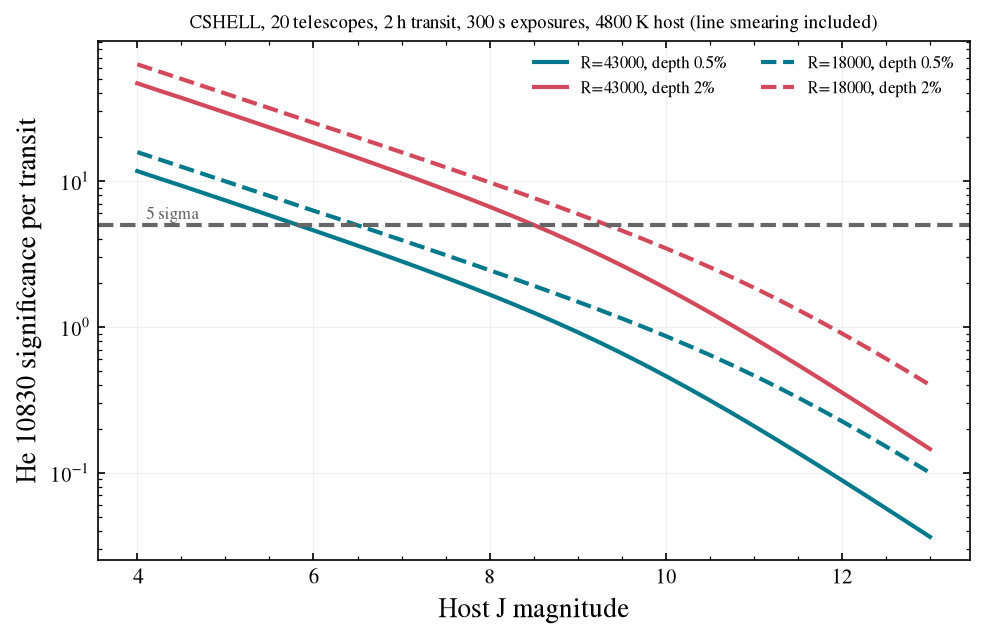

In [4]:
jmags = np.linspace(4, 13, 37)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for mode, ls in (("cshell_r43000", '-'), ("cshell_r18000", '--')):
    etc = he_setup(mode)
    for depth, color in ((0.005, 'C0'), (0.02, 'C1')):
        s = np.array([significance(etc, Source.blackbody(4800, j, "J"), depth) for j in jmags])
        ax.plot(jmags, s, ls=ls, color=color, label=f"R={etc.instrument.resolving_power:.0f}, depth {100*depth:g}%")
ax.axhline(5, color='0.4', ls='--'); ax.text(4.1, 5.5, "5 sigma", fontsize=8, color='0.4')
ax.set_yscale('log'); ax.set_xlabel("Host J magnitude"); ax.set_ylabel("He 10830 significance per transit")
ax.legend(fontsize=8, ncol=2); ax.set_title(f"CSHELL, {N_TEL} telescopes, 2 h transit, 300 s exposures, 4800 K host (line smearing included)", fontsize=9);

## Number of transits for a 5-sigma detection of a 1% line

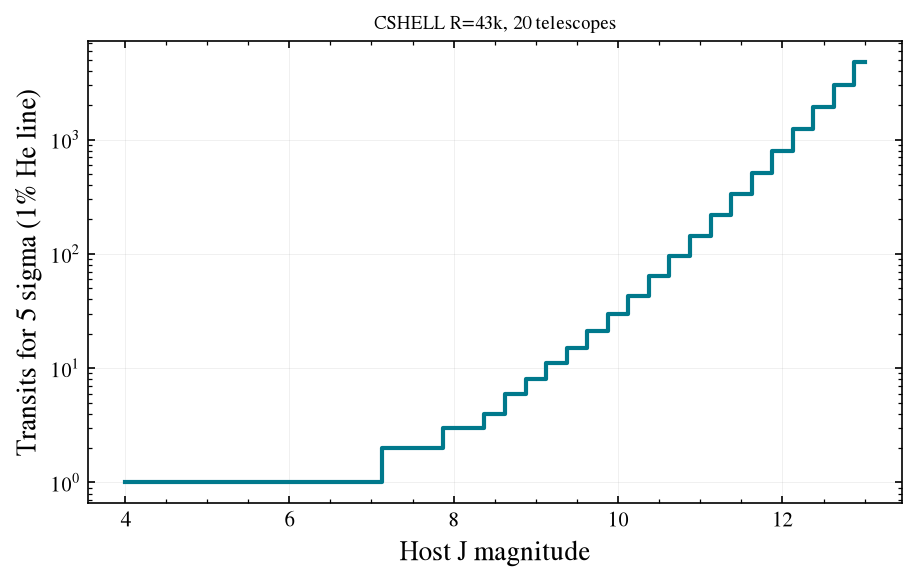

In [5]:
etc = he_setup("cshell_r43000")
n_transits = np.ceil((5/np.array([significance(etc, Source.blackbody(4800, j, "J"), 0.01) for j in jmags]))**2)
fig, ax = plt.subplots(figsize=(7, 4))
ax.step(jmags, n_transits, where='mid')
ax.set_yscale('log'); ax.set_xlabel("Host J magnitude"); ax.set_ylabel("Transits for 5 sigma (1% He line)")
ax.set_title("CSHELL R=43k, 20 telescopes", fontsize=9);

## Why read noise and the array size matter here

CSHELL's 22 e$^-$ read noise and 0.5 e$^-$/s dark current are large. With all fibers combined the
detector terms are paid once; with independent spectra they are paid $N$ times.

In [6]:
ns = [5, 10, 20, 40, 80]
src = Source.blackbody(4800, 9.0, "J")
for combine in ("fiber", "independent"):
    row = []
    for n in ns:
        etc = LFASTETC("cshell_r43000", telescope=Telescope(n, "18um", combine=combine), wavelength_min_nm=1081, wavelength_max_nm=1086)
        row.append(f"N={n}: {100*precision_per_transit(etc, src)[0]:.2f}%")
    print(f"{combine:12s} " + "  ".join(row))

fiber        N=5: 1.25%  N=10: 0.71%  N=20: 0.43%  N=40: 0.27%  N=80: 0.18%
independent  N=5: 2.47%  N=10: 1.75%  N=20: 1.23%  N=40: 0.87%  N=80: 0.62%


## Cross-correlation within one echelle setting (order-of-magnitude)

For completeness: a CCF over $N_{lines}$ planetary lines of individual contrast $\epsilon$
(relative to the star) in one 40 A window at 1.55 um gives per transit
$S/N_{CCF} \approx \epsilon\, \mathrm{SNR}_{resel} \sqrt{N_{lines} N_{exp}}$.
Here $\epsilon$ = 5e-4 is a per-line contrast relative to the star and $N_{lines}$ = 10-30 usable
water/CO lines in one 40 A window is a guess; with so few lines the He line is the better bet.

In [7]:
etc = LFASTETC("cshell_r43000", n_telescopes=20, wavelength_min_nm=1550, wavelength_max_nm=1554)
for name, (teff, jmag, _) in list(targets.items())[:3]:
    hmag = Source.blackbody(teff, jmag, "J").magnitude("H")
    r = etc.snr(Source.blackbody(teff, hmag, "H"), EXP)
    snr = float(np.median(r.snr))
    for n_lines in (10, 30):
        print(f"{name:12s} H={hmag:4.1f}: SNR/resel={snr:5.0f}; CCF S/N per transit (eps=5e-4, {n_lines} lines) = {5e-4*snr*np.sqrt(n_lines*N_IN):.1f}")

HD 189733 b  H= 5.8: SNR/resel=  159; CCF S/N per transit (eps=5e-4, 10 lines) = 1.2
HD 189733 b  H= 5.8: SNR/resel=  159; CCF S/N per transit (eps=5e-4, 30 lines) = 2.1
WASP-69 b    H= 7.7: SNR/resel=   58; CCF S/N per transit (eps=5e-4, 10 lines) = 0.4
WASP-69 b    H= 7.7: SNR/resel=   58; CCF S/N per transit (eps=5e-4, 30 lines) = 0.8
HAT-P-11 b   H= 7.3: SNR/resel=   73; CCF S/N per transit (eps=5e-4, 10 lines) = 0.6
HAT-P-11 b   H= 7.3: SNR/resel=   73; CCF S/N per transit (eps=5e-4, 30 lines) = 1.0
